# Klasifikasi Pesan Spam dan Ham Menggunakan Machine Learning

## Deskripsi Proyek

Proyek ini bertujuan mengklasifikasikan pesan atau email ke dalam dua kategori, yaitu **spam** dan **ham**. Spam adalah pesan yang tidak diinginkan, biasanya berisi promosi berlebihan, tawaran hadiah, atau ajakan mengeklik tautan tertentu. Ham adalah pesan normal yang relevan dan tidak tergolong spam.

Notebook ini melakukan pemeriksaan dataset, pembersihan teks, pembagian data latih dan data uji, perubahan teks menjadi fitur numerik dengan TF-IDF, pelatihan dua model, evaluasi hasil, serta pengujian pesan baru. Model yang dibandingkan adalah Multinomial Naive Bayes dan Logistic Regression.

## 1. Penjelasan Dataset

Notebook ini menggunakan file **`dataset_spam_ham_1600.csv`**. Berdasarkan kode yang digunakan, dataset perlu memiliki setidaknya dua kolom:

- **`text`**: isi pesan atau email yang akan dianalisis.
- **`label`**: kategori pesan, dengan nilai `spam` atau `ham`.

Nama file menunjukkan dataset yang direncanakan berisi 1.600 baris, tetapi jumlah baris dan distribusi label yang sebenarnya harus dipastikan dari hasil pemeriksaan pada sel berikutnya. Jangan menyimpulkan jumlah data atau keseimbangan kelas sebelum melihat output.

Setiap baris mewakili satu pesan. Kolom `text` menjadi masukan model, sedangkan kolom `label` menjadi jawaban/kategori yang dipelajari model. Dataset harus berada di folder kerja yang sama dengan notebook, atau lokasi file pada kode harus disesuaikan. Pastikan nama kolom dan penulisan label sesuai dengan yang dipakai kode.

## 2. Memanggil Library

Kode berikut memanggil library untuk membaca dan mengolah data, membuat grafik, membagi dataset, mengubah teks menjadi fitur TF-IDF, melatih model klasifikasi, dan mengevaluasi hasilnya. Jika library belum tersedia di lingkungan Jupyter, instal terlebih dahulu dengan perintah `pip install pandas numpy matplotlib seaborn scikit-learn`.

In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## 3. Memuat dan Memeriksa Dataset

Kode membaca file CSV ke dalam DataFrame `df`. `df.info()` menampilkan struktur data dan nilai non-kosong setiap kolom. `value_counts()` menghitung jumlah data pada setiap label, sedangkan `head()` menampilkan lima baris pertama agar format dataset dapat diperiksa.

Periksa apakah kolom `text` dan `label` tersedia, apakah ada nilai kosong, serta apakah label hanya berisi `spam` dan `ham`. Jika file tidak ditemukan, pindahkan CSV ke folder kerja notebook atau sesuaikan lokasi pada `pd.read_csv()`.

In [2]:
df = pd.read_csv('dataset_spam_ham_1600.csv')

print(df.info())
print(df['label'].value_counts())
display(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 1600 entries, 0 to 1599
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   id      1600 non-null   int64
 1   text    1600 non-null   str  
 2   label   1600 non-null   str  
dtypes: int64(1), str(2)
memory usage: 37.6 KB
None
label
spam    800
ham     800
Name: count, dtype: int64


,id,text,label
0,1,DISCOUNT SPECIAL! Beli sekarang dan dapatkan p...,spam
1,2,Rapat evaluasi bulanan ditunda hingga hari Jum...,ham
2,3,Jangan lupa membawa dokumen persyaratan saat h...,ham
3,4,Kesempatan emas! Investasi saham return 50% pe...,spam
4,5,"Berikut invoice bulanan layanan internet Anda,...",ham


## 4. Melihat Distribusi Label

Bagian ini menghitung jumlah pesan untuk setiap label dan menampilkannya dalam grafik batang. Grafik membantu melihat apakah jumlah pesan spam dan ham seimbang atau berbeda jauh. Perbedaan jumlah kelas dapat memengaruhi cara menafsirkan hasil evaluasi model.

label
spam    800
ham     800
Name: count, dtype: int64


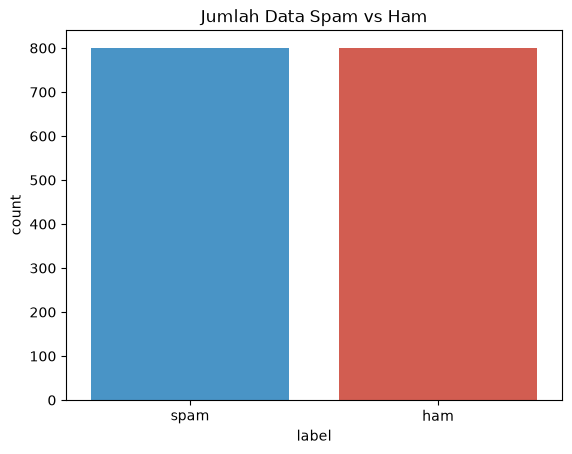

In [3]:
# Cek berapa jumlah spam dan ham
print(df['label'].value_counts())

# Plot grafik sederhana
sns.countplot(data=df, x='label', hue='label', palette=['#3498db', '#e74c3c'], legend=False)
plt.title('Jumlah Data Spam vs Ham')
plt.show()

## 5. Membersihkan Teks dan Mengubah Label

Fungsi `bersihkan_teks()` melakukan tiga langkah sederhana: mengubah teks menjadi huruf kecil, menghapus angka dan tanda baca, serta merapikan spasi berlebih. Hasilnya disimpan pada kolom `clean_text`.

Kolom `label` kemudian diubah menjadi angka pada kolom `target`: `spam` menjadi `1` dan `ham` menjadi `0`. Kolom teks asli tetap dipertahankan agar hasil pembersihan dapat dibandingkan. Pembersihan ini bersifat sederhana; penghapusan angka dan simbol dapat menghilangkan sebagian informasi yang mungkin berguna pada kasus tertentu.

In [4]:
# Fungsi pembersihan teks sederhana
def bersihkan_teks(text):
    text = text.lower() # ubah ke huruf kecil
    text = re.sub(r'[^a-zA-Z\s]', '', text) # hapus simbol/angka
    text = re.sub(r'\s+', ' ', text).strip() # rapikan spasi
    return text

# Terapkan ke dataframe
df['clean_text'] = df['text'].apply(bersihkan_teks)

# Ubah label spam=1, ham=0
df['target'] = df['label'].map({'spam': 1, 'ham': 0})

df[['text', 'clean_text', 'target']].head()

,text,clean_text,target
0,DISCOUNT SPECIAL! Beli sekarang dan dapatkan p...,discount special beli sekarang dan dapatkan po...,1
1,Rapat evaluasi bulanan ditunda hingga hari Jum...,rapat evaluasi bulanan ditunda hingga hari jum...,0
2,Jangan lupa membawa dokumen persyaratan saat h...,jangan lupa membawa dokumen persyaratan saat h...,0
3,Kesempatan emas! Investasi saham return 50% pe...,kesempatan emas investasi saham return per bul...,1
4,"Berikut invoice bulanan layanan internet Anda,...",berikut invoice bulanan layanan internet anda ...,0


## 6. Membagi Data Latih dan Data Uji

Variabel `X` berisi teks yang sudah dibersihkan, sedangkan `y` berisi label numerik. `train_test_split()` membagi data menjadi 80% data latih dan 20% data uji. `random_state=42` membuat pembagian dapat diulang, sementara `stratify=y` berusaha mempertahankan proporsi spam dan ham pada kedua bagian.

Data latih dipakai untuk membangun model. Data uji dipakai untuk menilai kinerja pada pesan yang tidak digunakan selama pelatihan.

In [5]:
X = df['clean_text']
y = df['target']

# Bagi data 80% train, 20% test
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Data Train:', len(x_train))
print('Data Test:', len(x_test))

Data Train: 1280
Data Test: 320


## 7. Mengubah Teks Menjadi Fitur TF-IDF

Algoritma machine learning memerlukan masukan numerik, sehingga teks diubah menjadi matriks fitur menggunakan `TfidfVectorizer`. TF-IDF memberikan bobot pada kata berdasarkan kepentingannya dalam kumpulan dokumen. Parameter `max_features=3000` membatasi jumlah fitur kata yang digunakan hingga paling banyak 3.000.

`fit_transform()` dipakai pada data latih untuk mempelajari kosakata dan mengubah teks. Data uji hanya diproses dengan `transform()` agar kosakata tidak dipelajari dari data uji. Ukuran matriks menunjukkan jumlah pesan dan fitur yang dihasilkan.

In [6]:
# Ubah teks ke matriks TF-IDF
vec = TfidfVectorizer(max_features=3000)

x_train_vec = vec.fit_transform(x_train)
x_test_vec = vec.transform(x_test)

print("Ukuran matriks train:", x_train_vec.shape)

Ukuran matriks train: (1280, 260)


## 8. Melatih dan Mengevaluasi Model Naive Bayes

`MultinomialNB` adalah algoritma Naive Bayes yang umum digunakan untuk klasifikasi teks berbasis fitur seperti frekuensi atau bobot kata. Model dilatih menggunakan fitur TF-IDF dan label data latih, lalu memprediksi label data uji.

Akurasi menunjukkan proporsi prediksi yang benar. `classification_report` menampilkan precision, recall, F1-score, dan support untuk setiap kelas. Precision mengukur ketepatan prediksi suatu kelas, recall mengukur seberapa banyak data kelas itu berhasil ditemukan, sedangkan F1-score merangkum precision dan recall.

In [7]:
# Latih model Naive Bayes
model_nb = MultinomialNB()
model_nb.fit(x_train_vec, y_train)

# Prediksi data test
pred_nb = model_nb.predict(x_test_vec)

# Evaluasi
print("Akurasi Naive Bayes:", accuracy_score(y_test, pred_nb))
print("\nClassification Report:\n", classification_report(y_test, pred_nb))

Akurasi Naive Bayes: 1.0

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       160
           1       1.00      1.00      1.00       160

    accuracy                           1.00       320
   macro avg       1.00      1.00      1.00       320
weighted avg       1.00      1.00      1.00       320



## 9. Melatih dan Mengevaluasi Model Logistic Regression

Bagian ini melatih model pembanding, yaitu Logistic Regression, dengan data fitur yang sama. Model kemudian memprediksi data uji dan menampilkan akurasi serta classification report.

Membandingkan dua algoritma pada pembagian data uji yang sama membantu melihat perbedaan kinerjanya. Model dengan akurasi tertinggi belum tentu selalu paling sesuai; perhatikan juga precision, recall, dan F1-score, khususnya untuk kelas spam.

In [8]:
# Latih model Logistic Regression
model_lr = LogisticRegression()
model_lr.fit(x_train_vec, y_train)

# Prediksi data test
pred_lr = model_lr.predict(x_test_vec)

# Evaluasi
print("Akurasi Logistic Regression:", accuracy_score(y_test, pred_lr))
print("\nClassification Report:\n", classification_report(y_test, pred_lr))

Akurasi Logistic Regression: 1.0

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       160
           1       1.00      1.00      1.00       160

    accuracy                           1.00       320
   macro avg       1.00      1.00      1.00       320
weighted avg       1.00      1.00      1.00       320



## 10. Membandingkan Confusion Matrix

Confusion matrix memperlihatkan jumlah prediksi benar dan salah untuk masing-masing kelas. Baris menunjukkan label sebenarnya dan kolom menunjukkan label prediksi, mengikuti urutan kelas yang digunakan oleh scikit-learn.

Untuk klasifikasi spam, perhatikan pesan spam yang salah diprediksi sebagai ham karena pesan berbahaya dapat lolos sebagai pesan normal. Perhatikan juga ham yang salah diprediksi sebagai spam karena pesan normal bisa masuk ke kategori spam. Gunakan angka pada grafik untuk menjelaskan kesalahan model secara konkret.

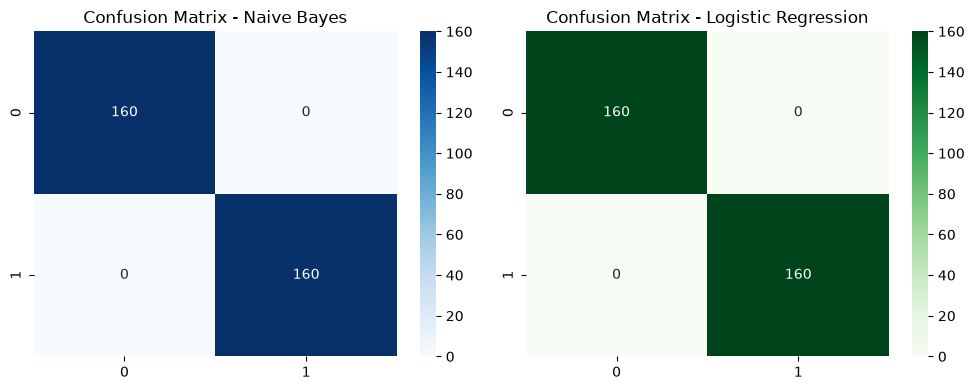

In [9]:
# Buat confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Heatmap Naive Bayes
sns.heatmap(confusion_matrix(y_test, pred_nb), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Confusion Matrix - Naive Bayes')

# Heatmap Logistic Regression
sns.heatmap(confusion_matrix(y_test, pred_lr), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('Confusion Matrix - Logistic Regression')

plt.tight_layout()
plt.show()

## 11. Menguji Pesan Baru

Fungsi `cek_email()` menerima kalimat baru, membersihkannya dengan fungsi yang sama, mengubahnya menggunakan TF-IDF yang sudah dilatih, lalu memprediksi kelas menggunakan model Naive Bayes.

Dua contoh di bawah hanya merupakan pengujian ilustratif. Hasil prediksi bergantung pada pola yang dipelajari dari dataset, sehingga tidak menjamin semua pesan serupa akan selalu diklasifikasikan dengan benar. Untuk mencoba pesan lain, panggil fungsi tersebut dengan teks yang ingin diuji.

In [10]:
# Fungsi untuk test kalimat baru
def cek_email(kalimat):
    kalimat_clean = bersihkan_teks(kalimat)
    v_input = vec.transform([kalimat_clean])
    hasil = model_nb.predict(v_input)[0]
    
    if hasil == 1:
        print(f"'{kalimat}' --> [SPAM]")
    else:
        print(f"'{kalimat}' --> [HAM / NORMAL]")

# Tes beberapa contoh email
cek_email("Selamat anda menang undian 50 juta rupiah klik bit.ly/menang")
cek_email("Jangan lupa kumpulkan tugas praktikum besok pagi ya")

'Selamat anda menang undian 50 juta rupiah klik bit.ly/menang' --> [SPAM]
'Jangan lupa kumpulkan tugas praktikum besok pagi ya' --> [HAM / NORMAL]


## 12. Kesimpulan dan Cara Membaca Hasil

Setelah semua sel dijalankan, catat jumlah baris dataset, jumlah spam dan ham, akurasi kedua model, precision, recall, F1-score, dan pola kesalahan pada confusion matrix. Gunakan angka yang benar-benar muncul pada output notebook; jangan menuliskan nilai evaluasi sebelum program dijalankan.

Kesimpulan sebaiknya menjawab: apakah model mampu membedakan spam dan ham pada data uji, model mana yang menunjukkan hasil lebih baik berdasarkan metrik yang tersedia, serta jenis kesalahan apa yang masih terjadi. Hasil evaluasi hanya menggambarkan kinerja pada dataset dan pembagian data yang digunakan.

# BAGIAN TAMBAHAN: ANALISIS ALGORITMA REGRESI

Bagian klasifikasi Spam/Ham di atas tetap dipertahankan. Materi berikut ditambahkan setelahnya sebagai pembahasan terpisah mengenai algoritma regresi.

## 1. Landasan Teori

Pemilihan algoritma regresi dipengaruhi oleh beberapa faktor utama:

- **Jenis data dan fitur:** karakteristik fitur, pencilan, korelasi antarfitur, serta kualitas data.
- **Ukuran dataset:** jumlah baris dan fitur memengaruhi waktu pelatihan, kebutuhan memori, dan kemampuan model mempelajari pola.
- **Linearitas:** hubungan fitur dengan target mungkin mendekati linear atau menunjukkan pola nonlinier.
- **Kebutuhan penerapan:** interpretabilitas, latensi prediksi, kemudahan pemeliharaan, dan risiko kesalahan pada domain tertentu.

### Algoritma yang dibahas

| Algoritma | Kegunaan / karakteristik |
|---|---|
| Linear Regression | Baseline sederhana saat hubungan dapat didekati secara linear; koefisien relatif mudah dijelaskan. |
| Ridge Regression | Regresi linear dengan regularisasi L2; berguna saat koefisien perlu distabilkan, terutama ketika fitur berkorelasi. |
| Lasso Regression | Regresi linear dengan regularisasi L1; dapat membuat sebagian koefisien menjadi nol. |
| Random Forest Regression | Gabungan banyak decision tree; dapat memodelkan pola nonlinier dan interaksi fitur. |
| Gradient Boosting Regression | Membangun model secara bertahap untuk memperbaiki kesalahan sebelumnya; dapat kuat pada data tabular. |
| Support Vector Regression (SVR) | Menggunakan margin toleransi kesalahan; kernel dapat membantu memodelkan hubungan nonlinier. |

Tidak ada algoritma yang selalu terbaik. Model perlu dibandingkan dengan pembagian data dan metrik evaluasi yang konsisten.

## 2. Memahami Metrik Evaluasi

### MAE — Mean Absolute Error
Rata-rata selisih absolut antara target aktual dan prediksi. **Semakin kecil semakin baik**, dengan nilai ideal 0. Satuan MAE sama dengan satuan target.

### MSE — Mean Squared Error
Rata-rata kuadrat kesalahan. **Semakin kecil semakin baik**, dengan nilai ideal 0. MSE memberi penalti lebih besar terhadap kesalahan besar dan satuannya merupakan kuadrat satuan target.

### RMSE — Root Mean Squared Error
Akar kuadrat MSE. Semakin kecil semakin baik dan satuannya sama dengan target.

### R² — Coefficient of Determination
Mengukur kemampuan model menjelaskan variasi target pada data evaluasi.
- **R² = 1:** prediksi sempurna.
- **R² = 0:** setara dengan baseline yang memprediksi rata-rata target pada data evaluasi, dalam pengertian skor R².
- **R² < 0:** lebih buruk daripada baseline tersebut.
- **Semakin mendekati 1 umumnya semakin baik.**

**Penting:** MAE dan MSE tidak harus kurang dari 1. Nilainya bergantung pada skala target. R² standar paling tinggi bernilai 1 dan dapat bernilai negatif.

In [ ]:
# 3. Import library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Library berhasil diimpor.")

## 4. Memuat dan Memahami Dataset

Dataset Diabetes bawaan Scikit-learn merupakan dataset regresi berukuran relatif kecil. Targetnya adalah ukuran kuantitatif perkembangan penyakit satu tahun setelah pengukuran awal. Dataset ini digunakan untuk demonstrasi pemodelan, bukan untuk keputusan medis.

In [ ]:
# Memuat dataset bawaan Scikit-learn (tidak perlu mengunduh file)
data = load_diabetes(as_frame=True)
X = data.data
y = data.target

print("Ukuran fitur:", X.shape)
print("Jumlah target:", y.shape[0])
display(X.head())
display(y.head())

print("\\nStatistik target:")
display(y.describe().to_frame(name="target"))

In [ ]:
# Pemeriksaan data
print("Nilai kosong pada fitur:", int(X.isna().sum().sum()))
print("Jumlah baris duplikat:", int(X.duplicated().sum()))
print("Jumlah fitur:", X.shape[1])
print("Jumlah observasi:", X.shape[0])

## 5. Membagi Data Menjadi Training dan Testing

Data testing disimpan untuk mengevaluasi model pada observasi yang tidak digunakan saat pelatihan. Semua model akan menggunakan pembagian data yang sama agar perbandingan lebih adil.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Data training:", X_train.shape)
print("Data testing :", X_test.shape)

## 6. Membuat dan Melatih Model

Standardisasi digunakan dalam pipeline untuk model linear ber-regularisasi dan SVR karena model tersebut dapat sensitif terhadap skala fitur. Pipeline memastikan scaler hanya dipelajari dari data training. Model berbasis pohon tidak memerlukan standardisasi untuk kebutuhan dasar eksperimen ini.

In [ ]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Lasso Regression": make_pipeline(StandardScaler(), Lasso(alpha=0.1, max_iter=10000)),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "SVR (RBF)": make_pipeline(StandardScaler(), SVR(kernel="rbf", C=10, epsilon=0.1))
}

results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    mse = mean_squared_error(y_test, y_pred)
    results.append({
        "Algoritma": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(results_df.round(3))

## 7. Visualisasi Perbandingan

Grafik berikut membandingkan MAE, RMSE, dan R² pada data testing. Untuk MAE dan RMSE, nilai lebih rendah lebih baik. Untuk R², nilai yang lebih tinggi umumnya lebih baik.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

metrics = [
    ("MAE", "MAE (lebih rendah lebih baik)"),
    ("RMSE", "RMSE (lebih rendah lebih baik)"),
    ("R2", "R² (lebih tinggi umumnya lebih baik)")
]

for ax, (column, title) in zip(axes, metrics):
    ordered = results_df.sort_values(column, ascending=(column != "R2"))
    ax.barh(ordered["Algoritma"], ordered[column])
    ax.set_title(title)
    ax.set_xlabel(column)
    ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

## 8. Grafik Nilai Aktual dan Prediksi

Titik yang semakin dekat dengan garis diagonal menunjukkan prediksi yang semakin dekat dengan nilai aktual. Grafik ini membantu melihat pola kesalahan, tetapi tetap perlu dibaca bersama metrik numerik.

In [ ]:
best_by_rmse = results_df.iloc[0]["Algoritma"]
best_pred = predictions[best_by_rmse]

plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_pred, alpha=0.75)
low = min(float(y_test.min()), float(best_pred.min()))
high = max(float(y_test.max()), float(best_pred.max()))
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Nilai aktual")
plt.ylabel("Nilai prediksi")
plt.title(f"Aktual vs Prediksi: {best_by_rmse}")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("Model dengan RMSE terkecil pada pengujian ini:", best_by_rmse)

## 9. Interpretasi Hasil

Jalankan semua sel terlebih dahulu, kemudian periksa tabel `results_df`.

- **MAE terkecil:** model memiliki rata-rata kesalahan absolut paling kecil pada data testing.
- **MSE terkecil:** model memiliki rata-rata kuadrat kesalahan paling kecil.
- **RMSE terkecil:** model memiliki akar rata-rata kuadrat kesalahan paling kecil.
- **R² terbesar:** model menjelaskan proporsi variasi target yang lebih besar pada data testing, dalam konteks evaluasi ini.

Model yang terbaik menurut satu metrik belum tentu terbaik menurut metrik lain. Perhatikan juga kebutuhan aplikasi, interpretabilitas, waktu prediksi, dan konsistensi hasil validasi. Karena ukuran dataset ini terbatas, hasil sebaiknya tidak digeneralisasi ke seluruh jenis data.

## 10. Kesimpulan

Eksperimen ini membandingkan Linear Regression, Ridge Regression, Lasso Regression, Random Forest Regression, Gradient Boosting Regression, dan Support Vector Regression menggunakan dataset regresi yang sama serta pembagian training-testing yang sama.

Pemilihan algoritma sebaiknya mempertimbangkan:
1. Jenis dan kualitas data.
2. Ukuran dataset dan jumlah fitur.
3. Linearitas atau kompleksitas pola.
4. MAE, MSE/RMSE, dan R² pada data yang tidak digunakan untuk pelatihan.
5. Kebutuhan interpretasi, kecepatan prediksi, dan risiko pada domain penerapan.

MAE dan MSE idealnya mendekati 0, sedangkan R² idealnya mendekati 1. Tidak ada batas universal bahwa MAE atau MSE harus kurang dari 1; skala target menentukan interpretasinya.

## 11. Referensi

1. Wallisch, C., Bach, P., Hafermann, L., Klein, N., Sauerbrei, W., & Steyerberg, E. W. (2022). *Review of guidance papers on regression modeling in statistical series of medical journals*. PLOS ONE, 17(1), e0262918. https://doi.org/10.1371/journal.pone.0262918
2. Bendersky, M., & Fridkin, S. (2026). *The Evolving Landscape of Modern Regression: A Systematic Review and Mapping Study of Penalized, Algorithmic, and Interpretable Models*. WIREs Data Mining and Knowledge Discovery, 16(1), e70078. https://doi.org/10.1002/widm.70078
3. Scikit-learn Developers. *Metrics and scoring: quantifying the quality of predictions*. https://scikit-learn.org/stable/modules/model_evaluation.html
4. Scikit-learn Developers. *LinearRegression*. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html
5. Scikit-learn Developers. *load_diabetes*. https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html

**Catatan:** referensi dokumentasi Scikit-learn merupakan dokumentasi teknis yang dapat diperbarui, bukan artikel jurnal. Pastikan detail bibliografi artikel jurnal diperiksa kembali sebelum dikumpulkan.